In [5]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
from collections import Counter

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

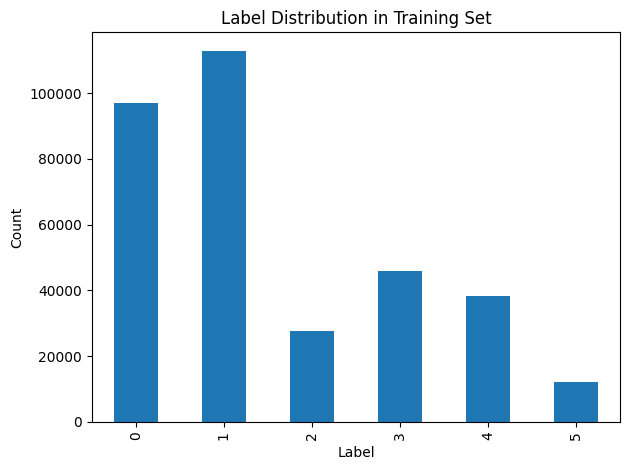

In [6]:
train = pd.read_csv('train_kaggle.csv')
test  = pd.read_csv('test_kaggle.csv')

label_counts = train['label'].value_counts().sort_index()
plt.figure()
label_counts.plot(kind='bar')
plt.title('Label Distribution in Training Set')
plt.xlabel('Label')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

import re
def clean_data(df):
    def clean(text):
        text = text.lower()
        text = re.sub(r"http\S+|www\S+|https\S+", "", text) 
        text = re.sub(r"[^a-z\s]", "", text)  
        text = re.sub(r"\s+", " ", text).strip()
        return text
    df['text'] = df['text'].apply(clean)
    return df



def remove_outliers(df, min_len=4, max_len=60):
    """
    Remove tweets that are too short or too long based on word count.
    Default range: 4 to 60 words.
    """
    def word_count(text):
        return len(text.split())

    df['word_count'] = df['text'].apply(word_count)
    df = df[(df['word_count'] >= min_len) & (df['word_count'] <= max_len)].copy()
    df.drop(columns=['word_count'], inplace=True)
    return df


train = clean_data(train)
train = remove_outliers(train)
test  = clean_data(test)

text_column   = 'text'
target_column = 'label'

X      = train[text_column].tolist()
y      = train[target_column].tolist()
X_test = test[text_column].tolist()

label_encoder = LabelEncoder()
y_encoded     = label_encoder.fit_transform(y)
num_classes   = len(label_encoder.classes_)

def build_vocab(texts, max_vocab_size=10000):
    counter = Counter()
    for text in texts:
        counter.update(text.lower().split())
    most_common = counter.most_common(max_vocab_size - 2)
    vocab = {word: idx + 2 for idx, (word, _) in enumerate(most_common)}
    vocab['<PAD>'] = 0
    vocab['<OOV>'] = 1
    return vocab

vocab = build_vocab(X)

def encode_text(texts, vocab, max_length=200):
    sequences = []
    for text in texts:
        tokens = text.lower().split()
        seq    = [vocab.get(tok, vocab['<OOV>']) for tok in tokens]
        if len(seq) < max_length:
            seq += [vocab['<PAD>']] * (max_length - len(seq))
        else:
            seq = seq[:max_length]
        sequences.append(seq)
    return torch.tensor(sequences)

X_encoded      = encode_text(X, vocab)
X_test_encoded = encode_text(X_test, vocab)

test_size = 0.2
seed      = 42
X_train, X_val, y_train, y_val = train_test_split(
    X_encoded,
    y_encoded,
    test_size=test_size,
    random_state=seed,
    stratify=y_encoded
)

y_train = torch.tensor(y_train)
y_val   = torch.tensor(y_val)

class TextDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is not None:
            return self.X[idx], self.y[idx]
        return self.X[idx]

batch_size   = 64
train_loader = DataLoader(TextDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TextDataset(X_val,   y_val),   batch_size=batch_size)
test_loader  = DataLoader(TextDataset(X_test_encoded), batch_size=batch_size)

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/30 | Train Loss: 0.4235 | Val Loss: 0.1793 | Val F1: 0.8910
Epoch 2/30 | Train Loss: 0.1510 | Val Loss: 0.1366 | Val F1: 0.9034
Epoch 3/30 | Train Loss: 0.1311 | Val Loss: 0.1274 | Val F1: 0.9084
Epoch 4/30 | Train Loss: 0.1201 | Val Loss: 0.1282 | Val F1: 0.9108
Epoch 5/30 | Train Loss: 0.1157 | Val Loss: 0.1278 | Val F1: 0.9106
Epoch 6/30 | Train Loss: 0.1123 | Val Loss: 0.1253 | Val F1: 0.9101
Epoch 7/30 | Train Loss: 0.1087 | Val Loss: 0.1281 | Val F1: 0.9094
Epoch 8/30 | Train Loss: 0.1016 | Val Loss: 0.1413 | Val F1: 0.9072
Early stopping triggered.


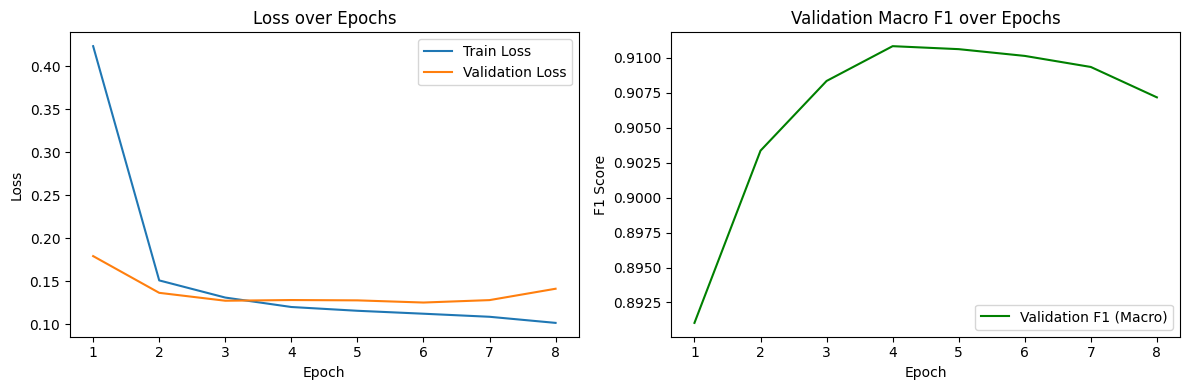

✅ Submission file created: submission_pytorch.csv


In [7]:
if '<PAD>' not in vocab:
    vocab['<PAD>'] = 0

num_classes = len(np.unique(y_train.numpy()))
env_vocab_size = len(vocab)

class MyModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim):
        super(MyModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=vocab['<PAD>'])
        self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, x):
        emb = self.embedding(x)
        _, h = self.rnn(emb)
        h = torch.cat([h[-2], h[-1]], dim=1)
        h = self.dropout(h)
        return self.fc(h)

embed_dim = 300
hidden_dim = 256
model = MyModel(env_vocab_size, embed_dim, hidden_dim, num_classes).to(device)

from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train.numpy()), y=y_train.numpy())
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=4e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2, verbose=True)

epochs = 30
best_f1 = 0
patience_counter = 0
early_stop_patience = 4

train_losses = []
val_losses = []
f1_scores = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)

    avg_train_loss = running_loss / len(train_loader.dataset)

    model.eval()
    val_loss = 0.0
    y_val_preds = []
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
            y_val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

    avg_val_loss = val_loss / len(val_loader.dataset)
    val_f1 = f1_score(y_val.numpy(), np.array(y_val_preds), average='macro')

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    f1_scores.append(val_f1)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val F1: {val_f1:.4f}")
    scheduler.step(val_f1)

    if val_f1 > best_f1:
        best_f1 = val_f1
        patience_counter = 0
        torch.save(model.state_dict(), 'best_model.pt')
    else:
        patience_counter += 1
        if patience_counter >= early_stop_patience:
            print("Early stopping triggered.")
            break

epochs_range = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss')
plt.plot(epochs_range, val_losses, label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, f1_scores, label='Validation F1 (Macro)', color='green')
plt.title('Validation Macro F1 over Epochs')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()
plt.tight_layout()
plt.show()

model.load_state_dict(torch.load('best_model.pt'))
model.eval()
test_preds = []
with torch.no_grad():
    for inputs in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        test_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())

submission = pd.DataFrame({'ID': test['ID'], 'label': label_encoder.inverse_transform(test_preds)})
submission.to_csv('submission_pytorch.csv', index=False)
print(" Submission file created: submission_pytorch.csv")


In [8]:
torch.save(model.state_dict(), 'best_model.pt')

import json
with open('vocab.json', 'w') as f:
    json.dump(vocab, f)

import pickle
with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

from google.colab import files
files.download('best_model.pt')
files.download('vocab.json')
files.download('label_encoder.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>